In [1]:
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df.head()

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1


In [3]:
df = df.drop(columns=['PLAYER', 'CS'])
x = df.iloc[:, 0:13]
y = df.iloc[:, 13]
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=17, test_size=0.2)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((372, 13), (93, 13), (372,), (93,))

In [4]:
class Node:
    def __init__(self, entropy, n_samples, counts, feature_idx=None, threshold=None, info_gain=None, left=None, right=None, value=None):

        # Decision Node
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.info_gain = info_gain
        self.left = left
        self.right = right
        
        # Leaf Node
        self.value = value

        # Node Data
        self.entropy = entropy
        self.n_samples = n_samples
        self.counts = counts

class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=2, max_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.max_features = max_features

    def build_tree(self, dataset, curr_depth=0):
        x, y = dataset[:, :-1], dataset[:, -1]
        n_samples, n_features = x.shape

        if n_samples >= self.min_samples_split and curr_depth < self.max_depth:
            best_split = self.best_split(dataset, n_features)

            if best_split['info_gain'] > 0:
                left_node = self.build_tree(best_split['left_dataset'], curr_depth + 1)
                right_node = self.build_tree(best_split['right_dataset'], curr_depth + 1)

                return Node(self.entropy(y), n_samples, Counter(y), best_split['feature_idx'], best_split['threshold'], best_split['info_gain'], left_node, right_node)

        leaf_value = Counter(y).most_common(1)[0][0]
        return Node(self.entropy(y), n_samples, Counter(y), value=leaf_value)

    def best_split(self, dataset, n_features):
        best_split = {'feature_idx': None, 'threshold': None, 'info_gain': -1, 'left_dataset': None, 'right_dataset': None}
        
        if self.max_features is None:
            features = range(n_features)
        else:
            features = np.random.choice(n_features, self.max_features, replace=False)
            
        for feature_idx in features:
            feature_values = dataset[:, feature_idx]
            thresholds = np.unique(feature_values)

            for threshold in thresholds:
                left_dataset, right_dataset = self.split(dataset, feature_idx, threshold)

                if len(left_dataset) and len(right_dataset):
                    parent_y, left_y, right_y = dataset[:, -1], left_dataset[:, -1], right_dataset[:, -1]

                    info_gain = self.information_gain(parent_y, left_y, right_y)
                    if info_gain > best_split['info_gain']:
                        best_split['feature_idx'] = feature_idx
                        best_split['threshold'] = threshold
                        best_split['info_gain'] = info_gain
                        best_split['left_dataset'] = left_dataset
                        best_split['right_dataset'] = right_dataset

        return best_split

    def split(self, dataset, feature_idx, threshold):
        left_dataset = np.array([row for row in dataset if row[feature_idx] <= threshold])
        right_dataset = np.array([row for row in dataset if row[feature_idx] > threshold])
        return left_dataset, right_dataset

    def information_gain(self, parent_y, left_y, right_y):
        left_weight = len(left_y) / len(parent_y)
        right_weight = len(right_y) / len(parent_y)

        information_gain = self.entropy(parent_y) - (left_weight * self.entropy(left_y) + right_weight * self.entropy(right_y))
        return information_gain

    def entropy(self, y):
        entropy = 0

        class_labels = np.unique(y)
        for class_label in class_labels:
            p = len(y[y == class_label]) / len(y)
            entropy += -p * np.log2(p)

        return entropy

    def fit(self, x, y):
        dataset = np.concatenate((np.array(x), np.array(y).reshape(-1, 1)), axis=1)
        self.root = self.build_tree(dataset)

    def predict(self, x):
        return [self.predict_class(row, self.root) for row in np.array(x)]

    def predict_class(self, row, node):
        if node.value != None:
            return node.value

        feature_val = row[node.feature_idx]
        if feature_val <= node.threshold:
            return self.predict_class(row, node.left)
        else:
            return self.predict_class(row, node.right)

    def print_tree(self, node=None, depth=0, indent="|   ", feature_names=None):
        prefix = indent * depth

        if node is None:
            node = self.root
            
        node_info = f"{"    " * (3 - depth)}-Entropy: {node.entropy:.04f} | n_samples: {node.n_samples} | {node.counts}"
        
        if node.value is not None:
            print(f"{prefix}|--- class: {node.value}{node_info}")
            return

        if feature_names is None:
            feature_label = f"Feature {node.feature_idx}"
        else:
            feature_label = feature_names[node.feature_idx]

        print(f"{prefix}|--- {feature_label} <= {node.threshold}{node_info}")
        self.print_tree(node.left, depth + 1, indent, feature_names)

        print(f"{prefix}|--- {feature_label} > {node.threshold}")
        self.print_tree(node.right, depth + 1, indent, feature_names)

In [5]:
class RandomForest:
    def __init__(self, n_trees=10, max_depth=2, min_samples_split=2, max_features=None):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.trees = []

    def fit(self, x, y):
        x, y = np.array(x), np.array(y)
        self.trees = []
        for _ in range(self.n_trees):
            tree = DecisionTree(min_samples_split=self.min_samples_split, max_depth=self.max_depth, max_features=self.max_features)
            
            # Bootstrapping
            n_samples = x.shape[0]
            indices = np.random.choice(n_samples, n_samples, replace=True)
            X_sample, y_sample = x[indices], y[indices]
            
            # Train on the bootstrap sample
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

    def predict(self, X):
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = np.swapaxes(tree_preds, 0, 1)
        y_pred = [Counter(sample_preds).most_common(1)[0][0] for sample_preds in tree_preds]
        return np.array(y_pred)

Score: 0.7419354838709677


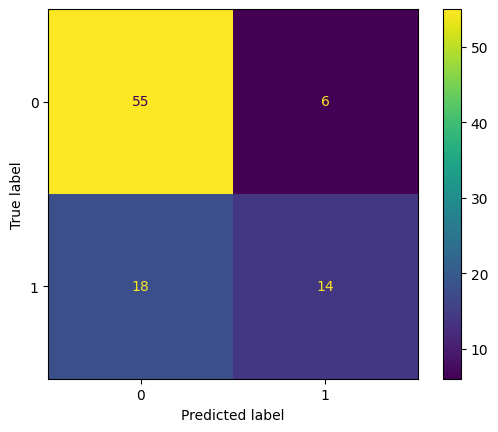

In [13]:
rf = RandomForest(min_samples_split=2, max_depth=2, max_features=4)
rf.fit(x_train, y_train)
y_pred = rf.predict(x_test)
print(f"Score: {np.mean(y_pred == y_test)}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [12]:
feature_names = list(x_train.columns)
for tree in rf.trees:
    tree.print_tree(feature_names=feature_names)
    print()
    print("_" * 100)

|--- R <= 1478.0            -Entropy: 0.8512 | n_samples: 372 | Counter({0.0: 269, 1.0: 103})
|   |--- RBI <= 1466.0        -Entropy: 0.6930 | n_samples: 328 | Counter({0.0: 267, 1.0: 61})
|   |   |--- class: 0.0    -Entropy: 0.6536 | n_samples: 321 | Counter({0.0: 267, 1.0: 54})
|   |--- RBI > 1466.0
|   |   |--- class: 1.0    -Entropy: 0.0000 | n_samples: 7 | Counter({1.0: 7})
|--- R > 1478.0
|   |--- AB <= 8120.0        -Entropy: 0.2668 | n_samples: 44 | Counter({1.0: 42, 0.0: 2})
|   |   |--- class: 1.0    -Entropy: 0.6840 | n_samples: 11 | Counter({1.0: 9, 0.0: 2})
|   |--- AB > 8120.0
|   |   |--- class: 1.0    -Entropy: 0.0000 | n_samples: 33 | Counter({1.0: 33})

____________________________________________________________________________________________________
|--- G <= 2368.0            -Entropy: 0.8953 | n_samples: 372 | Counter({0.0: 256, 1.0: 116})
|   |--- BA <= 0.306        -Entropy: 0.7375 | n_samples: 303 | Counter({0.0: 240, 1.0: 63})
|   |   |--- class: 0.0    -Entr